## Initialization

#### Import Library, find available devices

In [172]:
# Initialization code for 3.3 V SiGe LVR Load Regulation Testing.
# This block identifies and initializes the connected SMUs (Source Measure Units).
# If running for the first time, ensure the SMU names are correctly referenced in the subsequent code block.

# This program sweeps VIN for a fixed VREF and measures total quiescent current (IQ) and VOUT. 
# This program sets up a directory for all measurements taken at a specific temperature by prompting the user for the temperature.
# This program creates a .csv file to save the measurements for a VREF in the temperature directory. 

# The setup assumes the use of two SMUs:
# - One dedicated to VIN sweeps.
# - One Sinks a load current and measures VOUT.
import pyvisa                    # Importing the pyvisa library for instrument communication
import time                      # Importing the time module to handle time-related tasks (e.g., delays)
import matplotlib.pyplot as plt  # Importing matplotlib.pyplot for plotting graphs and visualizing data
import numpy as np               # Importing numpy for numerical operations, particularly with arrays
import pandas as pd              # Importing pandas as pd for data manipulation and analysis
import os                        # Importing os to interact with the operating system, such as handling file paths
import csv                       # Importing csv to read from and write to CSV files
from IPython.display import display, clear_output
from datetime import date           # Importing date to read current date
from collections import defaultdict

In [2]:
# Loads ICASL.py from a higher directory
# This file contains functions written by us that can be called with "ICASL.example_function_name"
import importlib.util    # Used to load python files more dynamically (ICASL.py)
quiet=True
current_dir = "."
target_file = "ICASL.py"
target_name = "ICASL"
while True:
    if not quiet: print(current_dir)
    # Check if ICASL is in the current directory
    ICASL_path = os.path.join(current_dir, target_file)
    if not quiet: print(ICASL_path)
    if os.path.isfile(ICASL_path):
        # Loads ICASL.py
        spec = importlib.util.spec_from_file_location(target_name, ICASL_path)
        ICASL = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(ICASL)
        break
    else:
        # Move one level up
        parent_dir = os.path.join(current_dir, "..")
        if not quiet: print(parent_dir)
        if current_dir == parent_dir:  # Reached the root directory
            raise ValueError("ICASL.py not found")
        else:
            current_dir = parent_dir
ICASL.test()

ICASL is loaded!


In [240]:
class BatteryEKF:
    def __init__(self, df_charge, df_discharge, Capacity):
        # Extract LUTs from the dataframes
        self.soc_charge_lut = df_charge["SOC"].values
        self.r0_charge_lut = df_charge["R0"].values
        self.r1_charge_lut = df_charge["R1"].values
        self.c1_charge_lut = df_charge["C1"].values
        self.r2_charge_lut = df_charge["R2"].values
        self.c2_charge_lut = df_charge["C2"].values

        self.soc_discharge_lut = df_discharge["SOC"].values
        self.r0_discharge_lut = df_discharge["R0"].values
        self.r1_discharge_lut = df_discharge["R1"].values
        self.c1_discharge_lut = df_discharge["C1"].values
        self.r2_discharge_lut = df_discharge["R2"].values
        self.c2_discharge_lut = df_discharge["C2"].values

        self.Q_cap = Capacity * 3600 # Ah to Ampere-seconds
        self.p_charge = np.poly1d(np.polyfit(self.soc_charge_lut, df_charge["OCV"].values, 5))
        self.p_charge_derivative = np.polyder(self.p_charge)
        self.p_discharge = np.poly1d(np.polyfit(self.soc_discharge_lut, df_discharge["OCV"].values, 5))
        self.p_discharge_derivative = np.polyder(self.p_discharge)


        # State: [SOC, Vc1, Vc2]
        self.x = np.array([[1.0], [0.0], [0.0]]) 
        self.P = np.eye(3) * .001
        self.charge_state = 'discharging'
        
        # Process noise usually scales with time, but keeping it simple for now
        self.Q = np.diag([1e-3, 1e-7, 1e-7]) 
        self.R = 1e-5

        self.voltage_history = []
        self.eoc_window = 10        # samples to track
        self.eoc_threshold = -0.010 # 10mV drop from peak triggers EOC
        self.is_fully_charged = False

    def update_charge_state(self, current, threshold=0.05):
        # Only update state when current is significant
        # During rest (current ≈ 0), state is preserved from last active period
        if -current > threshold:
            self.charge_state = 'charging'
        elif -current < -threshold:
            self.charge_state = 'discharging'

    def initialize_soc(self, measured_voltage, soc_points, ocv_points):
        """
        Call this ONCE before starting the loop to find a starting SOC.
        """
        # Use linear interpolation to find SOC from Voltage
        # Note: interp expects the x-coordinates (ocv) to be increasing
        initial_soc = np.interp(measured_voltage, ocv_points[::1], soc_points[::1])
        
        # Update the state vector
        self.x[0, 0] = initial_soc
        return initial_soc
    def get_parameters(self):
        current_soc = np.clip(self.x[0, 0], 0, 1)
        
        # Interpolate each parameter based on current SOC
        if self.charge_state == 'charging':  # charging LUTs
            r0 = np.interp(current_soc, self.soc_charge_lut, self.r0_charge_lut)
            r1 = np.interp(current_soc, self.soc_charge_lut, self.r1_charge_lut)
            c1 = np.interp(current_soc, self.soc_charge_lut, self.c1_charge_lut)
            r2 = np.interp(current_soc, self.soc_charge_lut, self.r2_charge_lut)
            c2 = np.interp(current_soc, self.soc_charge_lut, self.c2_charge_lut)
        else:  # discharging LUTs
            r0 = np.interp(current_soc, self.soc_discharge_lut, self.r0_discharge_lut)
            r1 = np.interp(current_soc, self.soc_discharge_lut, self.r1_discharge_lut)
            c1 = np.interp(current_soc, self.soc_discharge_lut, self.c1_discharge_lut)
            r2 = np.interp(current_soc, self.soc_discharge_lut, self.r2_discharge_lut)
            c2 = np.interp(current_soc, self.soc_discharge_lut, self.c2_discharge_lut)
            
        return r0, r1, c1, r2, c2
    def get_OCV(self, soc):
        # Ensure SOC stays in bounds [0, 1]
        soc = np.clip(soc, 0, 1)
        if self.charge_state == 'charging':
            return self.p_charge(soc)
        else:  # discharging
            return self.p_discharge(soc)

    # Derivative for the EKF Jacobian (H matrix)
    def get_dOCV_dSOC(self, soc):
        #p_derivative = np.polyder(p)
        if self.charge_state == 'charging':
            return self.p_charge_derivative(soc)
        else:  # discharging
            return self.p_discharge_derivative(soc)


    def predict(self, current, dt):
        # Fetch dynamic parameters for the current SOC
        r0, r1, c1, r2, c2 = self.get_parameters()
        
        exp1 = np.exp(-dt / (r1 * c1))
        exp2 = np.exp(-dt / (r2 * c2))
        
        A = np.array([[1, 0, 0], [0, exp1, 0], [0, 0, exp2]])
        B = np.array([[-dt / self.Q_cap], [r1 * (1 - exp1)], [r2 * (1 - exp2)]])
        
        self.x = A @ self.x + B * current
        lambda_factor = 1.001  # small forgetting factor
        self.P = lambda_factor * (A @ self.P @ A.T) + (self.Q * dt)
        if self.charge_state == 'charging':  # charging
                self.x[0, 0] = np.clip(self.x[0, 0], 0, 1.05)  # allow slight overcharge
        else:
            self.x[0, 0] = np.clip(self.x[0, 0], 0, 1.0)

        # self.P = A @ self.P @ A.T + (self.Q * dt)

    def update(self, measured_voltage, current, is_resting, rest_duration):
        # 2. Observation (h)
        # Vt = OCV(SOC) - I*R0 - Vc1 - Vc2
        self.update_charge_state(current)
        r0, r1, c1, r2, c2 = self.get_parameters()
        # ocv_predicted = measured_voltage - current * r0 - self.x[1, 0] - self.x[2, 0]
        # if ocv_predicted < 1.1 or ocv_predicted > 1.33: # We hit the 'knee'
        #     self.R = 1e-9 # Trust voltage more
        #     self.Q = np.diag([1e-3, 1e-6, 1e-6]) 
        # else:
        #     self.R = 1e-5 # Trust Coulomb counting more in the plateau
        #     self.Q = np.diag([1e-9, 1e-6, 1e-6]) 

        if is_resting:
            # Fraction of relaxation complete (0=just stopped, 1=fully relaxed)
            relaxation = 1 - np.exp(-rest_duration / (r1 * c1))
            # Scale measurement trust by how relaxed it is
            self.R = 1e-3 / (relaxation + 1e-3)  # high R when unrelaxed, low when relaxed
            self.Q = np.diag([1e-7, 1e-6, 1e-6])
        else:
            self.R = 1e-2  # during discharge, trust voltage less
            self.Q = np.diag([1e-2, 1e-7, 1e-7])
        soc_val = self.x[0, 0]


        v_predicted = self.get_OCV(soc_val) - current * r0 - self.x[1, 0] - self.x[2, 0]

        r0, r1, c1, r2, c2 = self.get_parameters()

        # 3. Jacobian (H) - Derivative of h with respect to x
        H = np.array([[self.get_dOCV_dSOC(soc_val), -1, -1]])
        
        # 4. Kalman Gain
        S = H @ self.P @ H.T + self.R
        K = self.P @ H.T @ np.linalg.inv(S)
        
        # 5. Update State and Covariance
        innovation = measured_voltage - v_predicted
        #innovation = measured_voltage - v_predicted
        # if abs(innovation) > 0.05:  # 50mV threshold
        #     # Filter is lost, increase uncertainty to force faster correction
        #     self.P = np.eye(3) * 0.1
        self.x = self.x + K * innovation
        self.P = (np.eye(3) - K @ H) @ self.P
        self.check_full_charge(measured_voltage, current)
        return self.x[0, 0] # Return estimated SOC

    def check_full_charge(self, voltage, current):
        # Only run during charging
        if -current <= 0:
            self.voltage_history = []  # reset when not charging
            return False
        
        self.voltage_history.append(voltage)
        
        # Need enough history to detect a peak
        if len(self.voltage_history) < self.eoc_window:
            return False
        
        # Keep window rolling
        if len(self.voltage_history) > self.eoc_window:
            self.voltage_history.pop(0)
        
        peak_voltage = max(self.voltage_history)
        dV = voltage - peak_voltage
        
        if dV < self.eoc_threshold:
            # Recalibrate SOC to 1.0 with high confidence
            self.x[0, 0] = 1.0
            self.P[0, 0] = 1e-6
            self.is_fully_charged = True
            return True
        
        return False

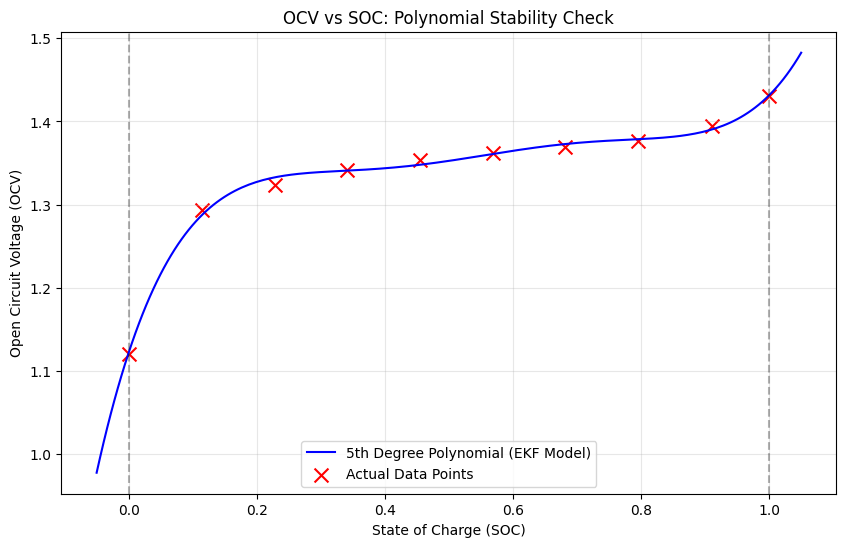

Data at 100% SOC: 1.12V
Poly at 100% SOC: 1.4315V


In [181]:
soc_range = np.linspace(-0.05, 1.05, 200) # Slightly wider to see edge behavior
ocv_poly = p(soc_range)

# 4. Plotting
plt.figure(figsize=(10, 6))
plt.plot(soc_range, ocv_poly, 'b-', label='5th Degree Polynomial (EKF Model)')
plt.scatter(soc_points, ocv_points, color='red', marker='x', s=100, label='Actual Data Points')

# Formatting
plt.axvline(0, color='black', linestyle='--', alpha=0.3)
plt.axvline(1, color='black', linestyle='--', alpha=0.3)
plt.xlabel('State of Charge (SOC)')
plt.ylabel('Open Circuit Voltage (OCV)')
plt.title('OCV vs SOC: Polynomial Stability Check')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

# 5. Check specific values at the edges
print(f"Data at 100% SOC: {ocv_points[0]}V")
print(f"Poly at 100% SOC: {p(1.0):.4f}V")

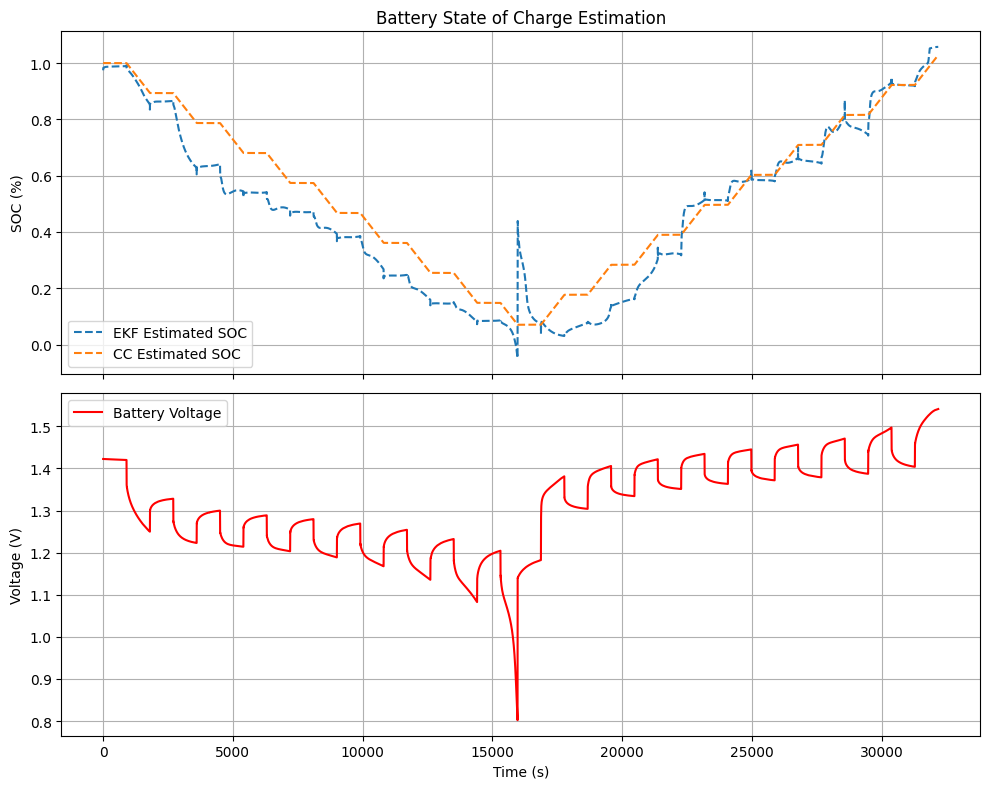

In [242]:
#df1 = pd.read_csv("Test_1/complete.csv")
df2 = pd.read_csv("Charging_with_stops/complete.csv")
#df1 = pd.read_csv("Discharging_3/complete.csv")
df1 = pd.read_csv("Discharging_2_truncated/complete.csv")

time_offset = df1["times"].iloc[-1]
df2_adjusted = df2.copy()
df2_adjusted["times"] = df2["times"] + time_offset

df = pd.concat([df1, df2_adjusted], ignore_index=True)


df_discharge = pd.read_csv("Discharging_2/BAT_ECM_2.csv")
df_charge = pd.read_csv("Charging_with_stops/BAT_ECM_Charge.csv")


capacity = 2.35
ekf = BatteryEKF(df_charge, df_discharge, capacity)
estimated_soc = []
CC_soc = []
init_soc =1
v_start = df['voltage'][0]
ekf.initialize_soc(v_start, df_charge["SOC"].values, df_charge["OCV"].values)
#ekf.initialize_soc(v_start, df_discharge["SOC"].values, df_discharge["OCV"].values)
rest_duration = 0
for i in range(len(df)):
    # Calculate dt dynamically
    if i == 0:
        dt = .1 # Small default for first step
        DOD = [0]
    else:
        dt = df["times"][i] - df["times"][i-1]
        DOD.append(DOD[-1]+(df["current"][i]*(dt)/3600))
    CC_soc.append(init_soc+DOD[i]/(capacity))

    is_resting = (df["current"][i] == 0)
    if is_resting:
        rest_duration += dt
    else:
        rest_duration = 0
    # Only run predict/update if dt is valid (prevents errors from duplicate timestamps)
    if dt > 0:
        ekf.predict(-df["current"][i], dt)
        soc = ekf.update(df["voltage"][i], -df["current"][i], is_resting, rest_duration)
        estimated_soc.append(soc)
    else:
        estimated_soc.append(estimated_soc[-1]) # Keep last value

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Plot 1: SOC (Top)
ax1.plot(df["times"], estimated_soc, '--', label='EKF Estimated SOC')
ax1.plot(df["times"], CC_soc, '--', label='CC Estimated SOC')
ax1.set_ylabel('SOC (%)')
ax1.legend()
ax1.grid()
ax1.set_title('Battery State of Charge Estimation')

# Plot 2: Voltage (Bottom)
ax2.plot(df["times"], df['voltage'], 'r-', label='Battery Voltage') # Changed color to red for clarity
ax2.set_ylabel('Voltage (V)')
ax2.set_xlabel('Time (s)')
ax2.legend()
ax2.grid()
plt.tight_layout() # Prevents labels from overlapping
plt.show()